In [1]:
import pandas as pd  # WHY: load processed tabular datasets
import numpy as np  # WHY: sequence construction and numerical operations
import joblib  # WHY: reload the scaler fitted only on training data

base = r"C:\sujit\SEM_5\SMART_GRID\processed_data"

X_train = pd.read_csv(base + r"\X_train.csv")
X_val = pd.read_csv(base + r"\X_val.csv")
X_test = pd.read_csv(base + r"\X_test.csv")

y_train = pd.read_csv(base + r"\y_train.csv").squeeze()
y_val = pd.read_csv(base + r"\y_val.csv").squeeze()
y_test = pd.read_csv(base + r"\y_test.csv").squeeze()

In [2]:
scaler = joblib.load(
    base + r"\price_scaler.pkl"
)  # WHY: use exactly the scaler learned from training data

X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.shape)
print(X_val_scaled.shape)
print(X_test_scaled.shape)

(24427, 23)
(5234, 23)
(5235, 23)


In [3]:
def create_sequences(X, y, lookback=48):
    X_seq = []  # WHY: store consecutive hourly feature windows
    y_seq = []  # WHY: store matching current-hour price

    for i in range(lookback - 1, len(X)):
        X_seq.append(
            X[i - lookback + 1:i + 1]
        )  # WHY: include current known features plus previous history
        y_seq.append(
            y[i]
        )  # WHY: predict actual price corresponding to current row

    return np.array(X_seq), np.array(y_seq)

In [4]:
X_train_seq, y_train_seq = create_sequences(
    X_train_scaled, y_train.to_numpy(), 48
)  # WHY: BiLSTM training windows

context = 47  # WHY: previous 47 rows + current row = 48-hour window

val_X_context = np.vstack([X_train_scaled[-context:], X_val_scaled])
val_y_context = np.concatenate([y_train.to_numpy()[-context:], y_val.to_numpy()])

X_val_seq, y_val_seq = create_sequences(
    val_X_context, val_y_context, 48
)

print(X_train_seq.shape, X_val_seq.shape)

(24380, 48, 23) (5234, 48, 23)


In [5]:
from xgboost import XGBRegressor  # WHY: selected tree-based price model

xgb = XGBRegressor(
    n_estimators=500,  # WHY: best validation tree count
    learning_rate=0.05,  # WHY: selected boosting rate
    max_depth=6,  # WHY: best depth/complexity tradeoff
    subsample=0.8,  # WHY: reduce overfitting
    colsample_bytree=0.8,  # WHY: diversify trees
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb.fit(X_train, y_train)  # WHY: validation must remain unseen by base-model training

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes 

In [6]:
import tensorflow as tf  # WHY: build the temporal forecasting model

tf.keras.utils.set_random_seed(42)

bilstm = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(48, 23)),  # WHY: 48 hours × 23 features
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64)),
    tf.keras.layers.Dense(32, activation="relu"),
    tf.keras.layers.Dense(1, activation="linear")
])

bilstm.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="mse",
    metrics=["mae"]
)

In [7]:
history = bilstm.fit(
    X_train_seq, y_train_seq,  # WHY: learn only from training period
    validation_data=(X_val_seq, y_val_seq),  # WHY: stop before overfitting
    epochs=60,
    batch_size=64,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    )],
    verbose=1
)

Epoch 1/60
381/381 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - loss: 408.2811 - mae: 11.7695 - val_loss: 36.7965 - val_mae: 4.4013
Epoch 2/60
381/381 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - loss: 17.9106 - mae: 3.0622 - val_loss: 21.4031 - val_mae: 3.2867
Epoch 3/60
381/381 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - loss: 10.1401 - mae: 2.3230 - val_loss: 15.4443 - val_mae: 2.6750
Epoch 4/60
381/381 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - loss: 6.9876 - mae: 1.9258 - val_loss: 10.5604 - val_mae: 2.2490
Epoch 5/60
381/381 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - loss: 5.4091 - mae: 1.6842 - val_loss: 8.5348 - val_mae: 1.9992
Epoch 6/60
381/381 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 4.5762 - mae: 1.5386 - val_loss: 7.4787 - val_mae: 1.8555
Epoch 7/60
381/381 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - loss: 4.1396 - mae: 1.4530 - val_loss: 6.9016 - val_mae: 1.7650
Epoch 8/60
381/381 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 3.9059 - mae: 1.4045 - val_loss: 6.6087 - val_mae: 1.7165
Epoch 9/60
381/381 ━━━━━━━━━━━━━━━━━━━

In [8]:
xgb_val_pred = xgb.predict(
    X_val
)  # WHY: XGBoost validation forecast

bilstm_val_pred = bilstm.predict(
    X_val_seq
).flatten()  # WHY: BiLSTM validation forecast

print(xgb_val_pred.shape)
print(bilstm_val_pred.shape)
print(y_val.shape)

164/164 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
(5234,)
(5234,)
(5234,)


In [9]:
from sklearn.linear_model import LinearRegression  # WHY: learn optimal model combination

stack_X_val = np.column_stack([
    xgb_val_pred,
    bilstm_val_pred
])  # WHY: base-model predictions become meta-model features

stacker = LinearRegression()  # WHY: keep hybrid simple and interpretable
stacker.fit(
    stack_X_val,
    y_val.to_numpy()
)  # WHY: learn how much weight each forecast deserves

print("XGBoost weight:", stacker.coef_[0])
print("BiLSTM weight :", stacker.coef_[1])
print("Intercept     :", stacker.intercept_)

XGBoost weight: 0.2562818
BiLSTM weight : 0.76498747
Intercept     : -1.5315895


In [10]:
test_X_context = np.vstack([
    X_val_scaled[-context:], X_test_scaled
])  # WHY: validation tail genuinely precedes the test period

test_y_context = np.concatenate([
    y_val.to_numpy()[-context:], y_test.to_numpy()
])

X_test_seq, y_test_seq = create_sequences(
    test_X_context, test_y_context, 48
)

print(X_test_seq.shape, y_test_seq.shape)

(5235, 48, 23) (5235,)


In [11]:
xgb_test_pred = xgb.predict(
    X_test
)  # WHY: tabular forecast on unseen test period

bilstm_test_pred = bilstm.predict(
    X_test_seq
).flatten()  # WHY: temporal forecast on identical test observations

stack_X_test = np.column_stack([
    xgb_test_pred,
    bilstm_test_pred
])  # WHY: create hybrid input from both forecasts

hybrid_pred = stacker.predict(
    stack_X_test
)  # WHY: produce final stacked electricity-price forecast

164/164 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

hybrid_mae = mean_absolute_error(y_test, hybrid_pred)
hybrid_rmse = mean_squared_error(y_test, hybrid_pred) ** 0.5
hybrid_r2 = r2_score(y_test, hybrid_pred)

actual = y_test.to_numpy()
nonzero = actual != 0
hybrid_mape = np.mean(
    np.abs((actual[nonzero] - hybrid_pred[nonzero]) / actual[nonzero])
) * 100

In [13]:
print(f"HYBRID MAE  : {hybrid_mae:.4f}")
print(f"HYBRID RMSE : {hybrid_rmse:.4f}")
print(f"HYBRID MAPE : {hybrid_mape:.2f}%")
print(f"HYBRID R²   : {hybrid_r2:.4f}")

HYBRID MAE  : 1.0618
HYBRID RMSE : 1.5096
HYBRID MAPE : 1.56%
HYBRID R²   : 0.9636


In [14]:
import os  # WHY: keep model artifacts in one folder
import joblib  # WHY: serialize the trained meta-model

os.makedirs("saved_models", exist_ok=True)

joblib.dump(
    stacker,
    "saved_models/price_hybrid_stacker.pkl"
)  # WHY: preserve learned XGBoost/BiLSTM combination weights

print("Hybrid stacker saved.")

Hybrid stacker saved.


In [15]:
hybrid_result = pd.DataFrame([{
    "model": "XGBoost + BiLSTM",
    "mae": hybrid_mae,
    "rmse": hybrid_rmse,
    "mape": hybrid_mape,
    "r2": hybrid_r2
}])  # WHY: preserve final metrics for report comparison

hybrid_result.to_csv(
    "saved_models/hybrid_results.csv", index=False
)

| Model                |      MAE ↓ |     RMSE ↓ |    MAPE ↓ |       R² ↑ |
| -------------------- | ---------: | ---------: | --------: | ---------: |
| ANN                  |     1.4398 |     1.9269 |     2.15% |     0.9407 |
| XGBoost              |     1.4381 |     1.9216 |     2.12% |     0.9411 |
| BiLSTM 48 h          |     1.1227 |     1.6019 |     1.65% |     0.9590 |
| **XGBoost + BiLSTM** | **1.0618** | **1.5096** | **1.56%** | **0.9636** |


In [22]:
import numpy as np  # WHY: convert values into consistent 1-D arrays
import pandas as pd  # WHY: create an actual-vs-predicted comparison table

actual = np.asarray(y_test).flatten()  # WHY: actual unseen test prices
predicted = np.asarray(hybrid_pred).flatten()  # WHY: hybrid model predictions

assert len(actual) == len(predicted), "Actual and prediction lengths do not match"

comparison = pd.DataFrame({
    "Actual_Price": actual,
    "Hybrid_Predicted_Price": predicted
})

comparison["Error"] = actual - predicted
comparison["Absolute_Error"] = np.abs(actual - predicted)

print(comparison.head(20))

    Actual_Price  Hybrid_Predicted_Price     Error  Absolute_Error
0          70.19               71.777008 -1.587008        1.587008
1          67.31               68.187378 -0.877378        0.877378
2          68.05               67.044418  1.005582        1.005582
3          65.97               65.607697  0.362303        0.362303
4          57.81               60.882572 -3.072572        3.072572
5          56.88               58.482319 -1.602319        1.602319
6          57.40               58.120415 -0.720415        0.720415
7          57.92               59.301605 -1.381605        1.381605
8          65.66               64.956955  0.703045        0.703045
9          68.70               68.135849  0.564151        0.564151
10         70.13               72.020584 -1.890584        1.890584
11         71.36               70.980652  0.379348        0.379348
12         71.11               72.456665 -1.346665        1.346665
13         72.53               73.231216 -0.701216        0.70

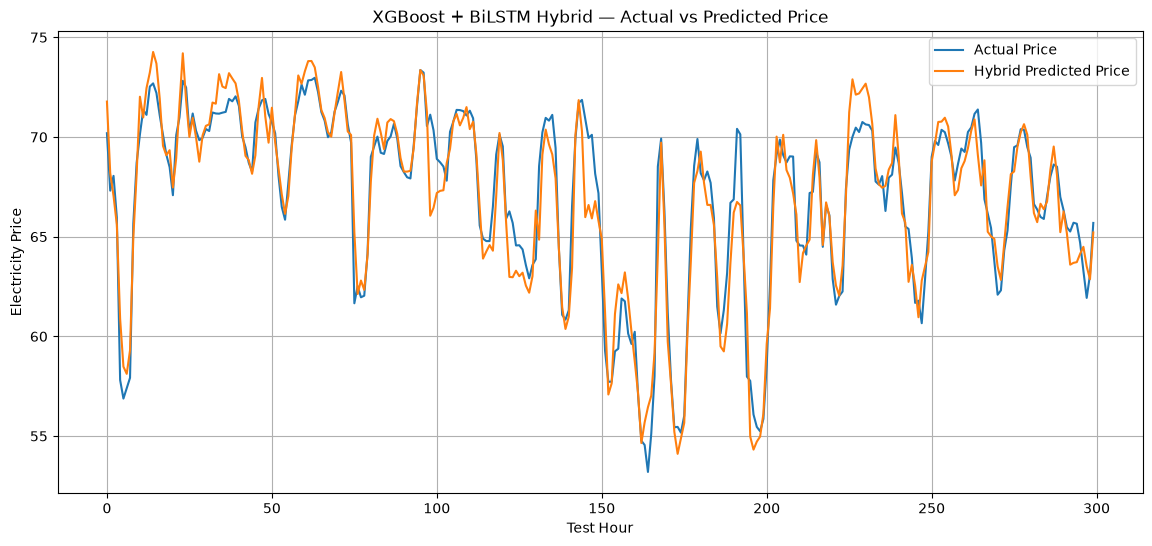

In [23]:
import matplotlib.pyplot as plt  # WHY: visually compare real and forecast prices

samples = 300  # WHY: keep the graph readable

plt.figure(figsize=(14, 6))
plt.plot(actual[:samples], label="Actual Price")
plt.plot(predicted[:samples], label="Hybrid Predicted Price")

plt.xlabel("Test Hour")
plt.ylabel("Electricity Price")
plt.title("XGBoost + BiLSTM Hybrid — Actual vs Predicted Price")
plt.legend()
plt.grid(True)
plt.show()

In [24]:
comparison.to_csv(
    "saved_models/hybrid_actual_vs_predicted.csv",
    index=False
)

print("Hybrid actual-vs-predicted comparison saved.")

Hybrid actual-vs-predicted comparison saved.


COMPARISON

In [28]:
random_samples = comparison.sample(
    n=20,
    random_state=42
).sort_index()  # WHY: randomly select 20 reproducible unseen test samples

print(random_samples[
    ["Actual", "BiLSTM", "Hybrid", "BiLSTM_Error", "Hybrid_Error"]
])

      Actual     BiLSTM     Hybrid  BiLSTM_Error  Hybrid_Error
79     64.16  63.872070  64.079880      0.287930      0.080120
80     69.01  67.060989  67.775848      1.949011      1.234152
157    61.76  63.155777  63.208988      1.395777      1.448988
422    66.18  65.171471  65.307938      1.008529      0.872062
426    65.10  64.352188  64.577637      0.747812      0.522363
1094   76.35  75.250763  75.160233      1.099237      1.189767
1268   71.56  71.494186  71.629211      0.065814      0.069211
1533   71.90  73.082130  73.121017      1.182130      1.221017
1859   73.97  75.917480  75.872589      1.947480      1.902589
2268   81.31  82.617798  83.307449      1.307798      1.997449
2543   84.49  86.986832  85.870148      2.496832      1.380148
2842   76.29  76.455193  76.917999      0.165193      0.627999
3075   63.22  64.145508  63.117702      0.925508      0.102298
3652   64.53  64.647812  64.507812      0.117812      0.022188
3869   48.06  48.710636  48.322697      0.650636      0

In [29]:
random_samples = random_samples.copy()

random_samples["Better_Model"] = np.where(
    random_samples["Hybrid_Error"] < random_samples["BiLSTM_Error"],
    "Hybrid",
    "BiLSTM"
)  # WHY: identify the closer prediction for each random test point

print(random_samples[
    ["Actual", "BiLSTM", "Hybrid",
     "BiLSTM_Error", "Hybrid_Error", "Better_Model"]
])

      Actual     BiLSTM     Hybrid  BiLSTM_Error  Hybrid_Error Better_Model
79     64.16  63.872070  64.079880      0.287930      0.080120       Hybrid
80     69.01  67.060989  67.775848      1.949011      1.234152       Hybrid
157    61.76  63.155777  63.208988      1.395777      1.448988       BiLSTM
422    66.18  65.171471  65.307938      1.008529      0.872062       Hybrid
426    65.10  64.352188  64.577637      0.747812      0.522363       Hybrid
1094   76.35  75.250763  75.160233      1.099237      1.189767       BiLSTM
1268   71.56  71.494186  71.629211      0.065814      0.069211       BiLSTM
1533   71.90  73.082130  73.121017      1.182130      1.221017       BiLSTM
1859   73.97  75.917480  75.872589      1.947480      1.902589       Hybrid
2268   81.31  82.617798  83.307449      1.307798      1.997449       BiLSTM
2543   84.49  86.986832  85.870148      2.496832      1.380148       Hybrid
2842   76.29  76.455193  76.917999      0.165193      0.627999       BiLSTM
3075   63.22

In [30]:
print(
    random_samples["Better_Model"].value_counts()
)  # WHY: count which model performed better on the random subset

print("\nRandom Sample MAE:")
print("BiLSTM :", random_samples["BiLSTM_Error"].mean())
print("Hybrid :", random_samples["Hybrid_Error"].mean())

Better_Model
Hybrid    13
BiLSTM     7
Name: count, dtype: int64

Random Sample MAE:
BiLSTM : 1.1699402084350585
Hybrid : 0.9815511398315426


In [36]:
import tensorflow as tf  # WHY: reload the trained ANN
import joblib  # WHY: reload the ANN input scaler

ann_model = tf.keras.models.load_model(
    "saved_models/price_ann.keras"
)  # WHY: use the final trained ANN

ann_scaler = joblib.load(
    "saved_models/price_scaler.pkl"
)  # WHY: ANN requires the scaler fitted for that final model

X_test_ann = ann_scaler.transform(X_test)  # WHY: ANN expects scaled features
ann_test_pred = ann_model.predict(X_test_ann).flatten()

164/164 ━━━━━━━━━━━━━━━━━━━━ 0s 917us/step


In [42]:
import numpy as np  # WHY: reproducible random sample selection

rng = np.random.default_rng(42)

indices = np.sort(
    rng.choice(
        len(y_test),
        size=20,
        replace=False
    )
)  # WHY: randomly select 20 unique unseen test observations

print("Selected indices:", indices)

Selected indices: [ 448  465  492  670 1052 2260 2290 2357 2685 2751 3415 3642 3752 3846
 3979 4037 4111 4395 4482 5099]


In [43]:
actual_random = np.asarray(y_test).flatten()[indices]

ann_random = np.asarray(
    ann_test_pred
).flatten()[indices]

xgb_random = np.asarray(
    xgb_test_pred
).flatten()[indices]

bilstm_random = np.asarray(
    bilstm_test_pred
).flatten()[indices]

hybrid_random = np.asarray(
    hybrid_pred
).flatten()[indices]

In [44]:
actual_random = np.asarray(y_test).flatten()[indices]
ann_random = np.asarray(ann_test_pred).flatten()[indices]
xgb_random = np.asarray(xgb_test_pred).flatten()[indices]
bilstm_random = np.asarray(bilstm_test_pred).flatten()[indices]
hybrid_random = np.asarray(hybrid_pred).flatten()[indices]

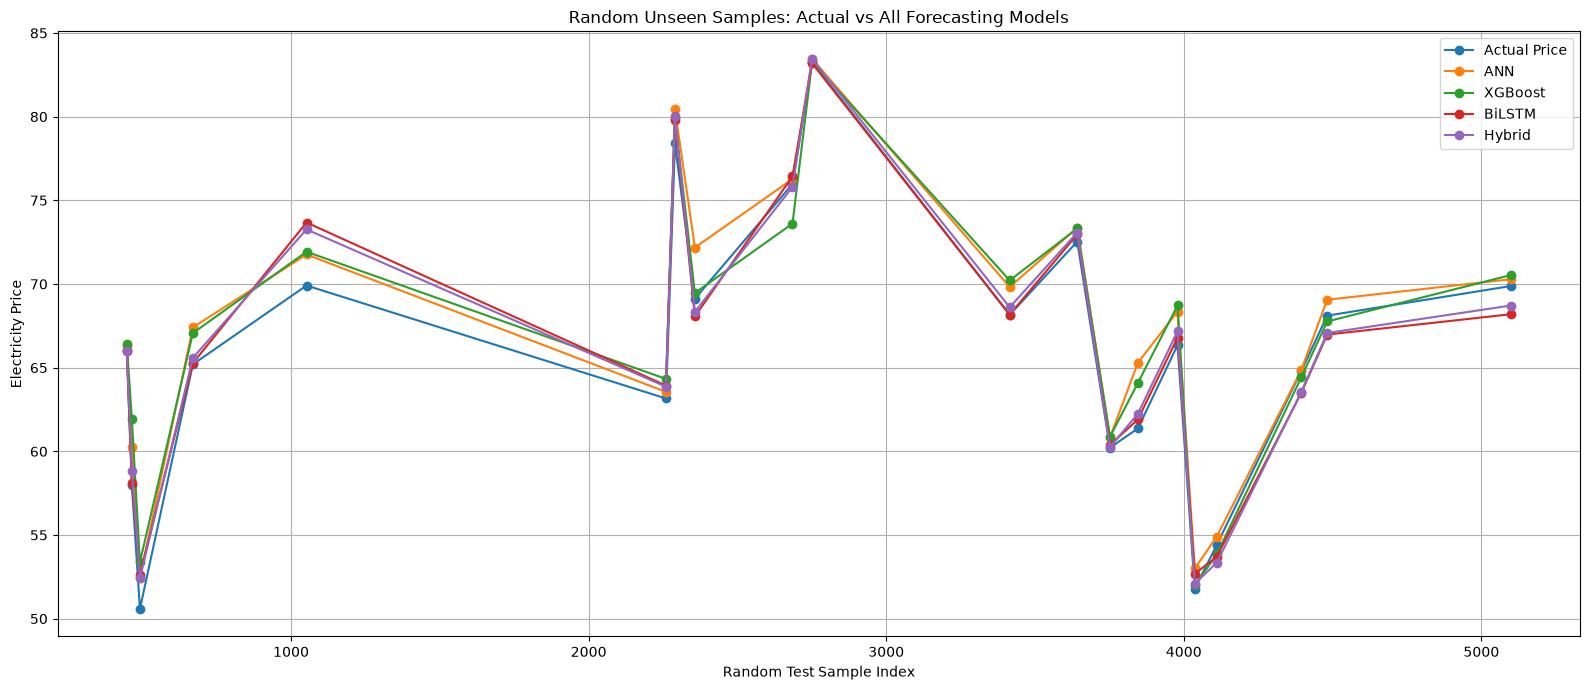

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 7))

plt.plot(indices, actual_random, marker="o", label="Actual Price")
plt.plot(indices, ann_random, marker="o", label="ANN")
plt.plot(indices, xgb_random, marker="o", label="XGBoost")
plt.plot(indices, bilstm_random, marker="o", label="BiLSTM")
plt.plot(indices, hybrid_random, marker="o", label="Hybrid")
plt.xlabel("Random Test Sample Index")
plt.ylabel("Electricity Price")
plt.title("Random Unseen Samples: Actual vs All Forecasting Models")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()


In [47]:
random_comparison = pd.DataFrame({
    "Actual": actual_random,
    "ANN": ann_random,
    "XGBoost": xgb_random,
    "BiLSTM": bilstm_random,
    "Hybrid": hybrid_random
}, index=indices)

print(random_comparison.round(2))

      Actual        ANN    XGBoost     BiLSTM     Hybrid
448    66.04  66.279999  66.410004  66.010002  65.989998
465    57.98  60.250000  61.939999  58.130001  58.810001
492    50.58  52.450001  53.369999  52.630001  52.410000
670    65.20  67.400002  67.070000  65.269997  65.589996
1052   69.91  71.760002  71.930000  73.680000  73.260002
2260   63.16  63.549999  64.330002  63.930000  63.860001
2290   78.40  80.440002  79.910004  79.830002  80.019997
2357   69.12  72.180000  69.459999  68.059998  68.339996
2685   75.98  76.269997  73.610001  76.430000  75.800003
2751   83.27  83.459999  83.290001  83.190002  83.449997
3415   68.16  69.820000  70.220001  68.169998  68.610001
3642   72.54  73.370003  73.320000  72.959999  73.080002
3752   60.22  60.830002  60.869999  60.380001  60.259998
3846   61.37  65.300003  64.089996  61.910000  62.259998
3979   66.35  68.349998  68.720001  66.790001  67.169998
4037   51.80  53.000000  51.990002  52.680000  52.090000
4111   54.41  54.910000  53.849

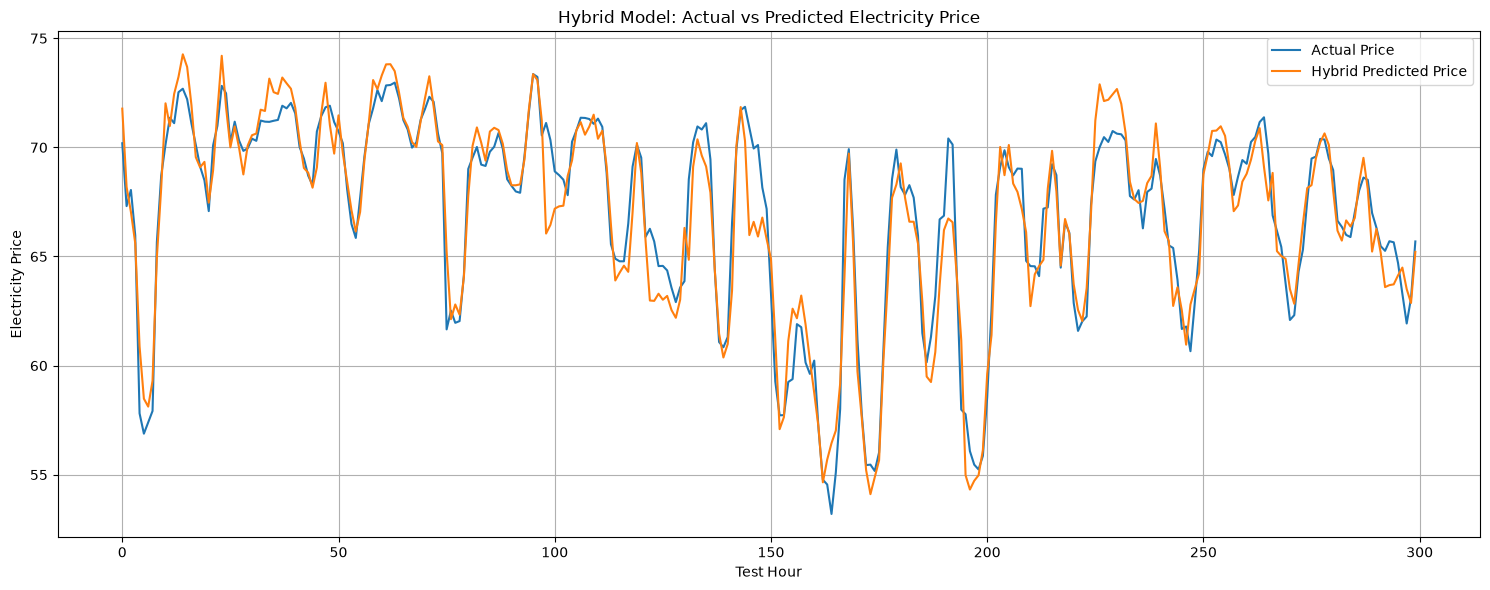

In [33]:
import matplotlib.pyplot as plt  # WHY: visualize actual and predicted price trends
import numpy as np  # WHY: convert values into clean arrays

actual = np.asarray(y_test).flatten()
predicted = np.asarray(hybrid_pred).flatten()

samples = 300  # WHY: keeps the line graph readable

plt.figure(figsize=(15, 6))
plt.plot(actual[:samples], label="Actual Price")
plt.plot(predicted[:samples], label="Hybrid Predicted Price")

plt.xlabel("Test Hour")
plt.ylabel("Electricity Price")
plt.title("Hybrid Model: Actual vs Predicted Electricity Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

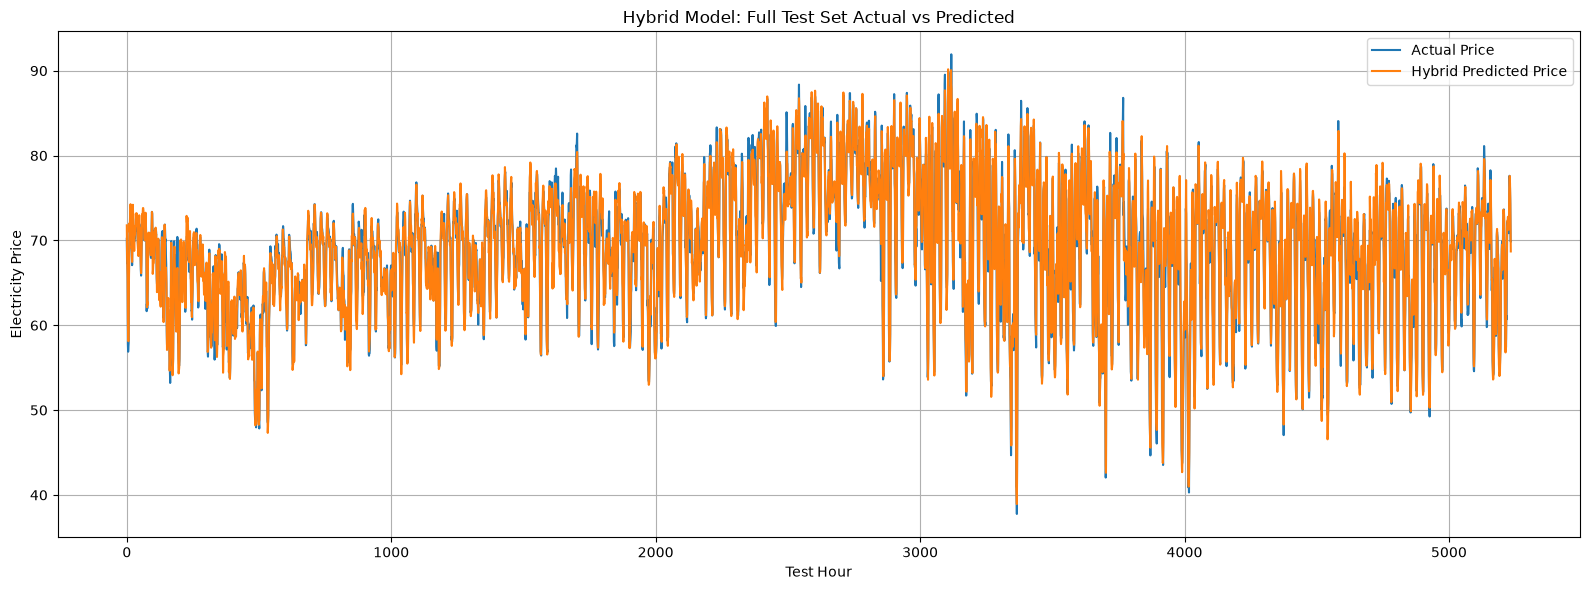

In [34]:
plt.figure(figsize=(16, 6))

plt.plot(actual, label="Actual Price")
plt.plot(predicted, label="Hybrid Predicted Price")

plt.xlabel("Test Hour")
plt.ylabel("Electricity Price")
plt.title("Hybrid Model: Full Test Set Actual vs Predicted")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()